# Machine Learning Assignment 2
## Topic: Comparison of five classification models
### BITS ID: 2026CT05058
### Name: Anjumol P
---

## 1. Problem statement
The objective of this project is to build and compare multiple machine learning classification models that can predict whether a customer will subscribe to a term deposit based on demographic information, financial status, previous marketing interactions, and campaign-related attributes



In [1]:
# Import required libraries
import os
import zipfile
import urllib.request
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
os.makedirs("model", exist_ok=True)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Download and load bank-additional-full.csv



In [2]:
#Download and load bank-additional-full.csv
#The code downloads the archive and extracts the exact file bank-additional-full.csv

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip"
ZIP_PATH = "bank-additional.zip"
EXTRACT_DIR = "bank_marketing_data"

# Create the target directory and fetch/extract the remote dataset archive only if the final CSV is not already present
if not os.path.exists(os.path.join(EXTRACT_DIR, "bank-additional", "bank-additional-full.csv")):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

DATA_PATH = os.path.join(EXTRACT_DIR, "bank-additional", "bank-additional-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset file:", DATA_PATH)
print("Dataset shape:", df.shape)
print("First five rows of dataset:")
display(df.head())
print("\nFeature names:")
print(df.columns.tolist())

Dataset file: bank_marketing_data/bank-additional/bank-additional-full.csv
Dataset shape: (41188, 21)
First five rows of dataset:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



Feature names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


## 3. DataSet Description

This dataset has been selected because of following reasons:

* 41188 instances (> 1000 required)
* 20 features (> 12 required)
* Contains numerical and categorical features
* Requires missing value handling
* Exhibits class imbalance, allowing meaningful model comparison
* Suitable for evaluating multiple binary classification algorithms on a real-world marketing prediction problem

The target y indicates whether the client subscribed to a term deposit

Dataset dimensions: (41188, 21)

Data types:


,data_type
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object



Count of 'unknown' values by column:


,unknown_count
default,8597
education,1731
housing,990
loan,990
job,330
marital,80



Missing values before preprocessing:


,missing_count
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0



Duplicate rows: 12

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


,count,percentage
y,,
no,36548,88.73
yes,4640,11.27


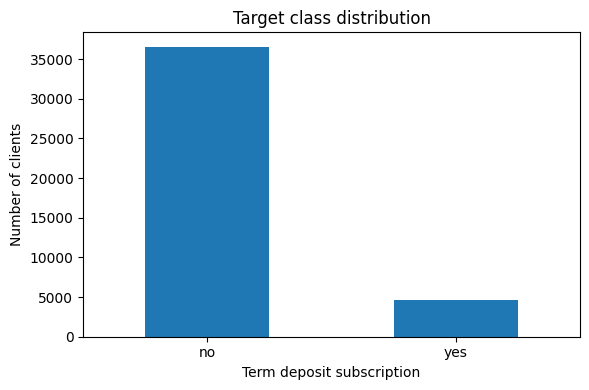

In [3]:
print("Dataset dimensions:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nCount of 'unknown' values by column:")
unknown_counts = (df == "unknown").sum().sort_values(ascending=False)
display(unknown_counts[unknown_counts > 0].to_frame("unknown_count"))

print("\nMissing values before preprocessing:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().T)

#Count of occurrences of each category ('yes' or 'no') in the binary classification target column
tgt_counts = df["y"].value_counts()

#Compute relative frequency (proportion) of classes and convert to percentages with rounding
tgt_percent = df["y"].value_counts(normalize=True) * 100

#Construct a structured summary DataFrame showing the exact size and relative representation of each class
target_summary = pd.DataFrame({
    "count": tgt_counts,
    "percentage": tgt_percent.round(2)
})
display(target_summary)

# Plot a bar chart showing the absolute frequency of the target labels in sorted index order
ax = tgt_counts.reindex(["no", "yes"]).plot(kind="bar", rot=0, figsize=(6, 4))
ax.set_title("Target class distribution")
ax.set_xlabel("Term deposit subscription")
ax.set_ylabel("Number of clients")
plt.tight_layout()
plt.show()

## 4. Data preprocessing

The following preprocessing steps are used:

1. Remove duplicate rows.
2. Treat categorical unknown values as missing.
3. Encode the target: no = 0 and yes = 1.
4. Remove feature ‘duration ‘to prevent target leakage
5. Split the data into 80% training and 20% testing using a fixed random seed and stratification.
6. Impute numerical missing values using the training median.
7. Impute categorical missing values using the most frequent training category.
8. One-hot encode categorical variables and standardize numerical variables.

All imputers, encoders and scalers are inside a scikit-learn pipeline. Therefore, they are fitted on training data only and then applied to test data, avoiding data leakage.

In [4]:
# Remove duplicate records to maintain dataset integrity
df = df.drop_duplicates().reset_index(drop=True)

# Identify categorical descriptors and replace the
# "unknown" with NaN to indicate missing information for subsequent imputation
social_categorical = df.select_dtypes(include=["object"]).columns.tolist()
for col in social_categorical:
    df[col] = df[col].replace("unknown", np.nan)

# Normalize target labels (handling integer values, string values, and missing values)
# Map 'no' (or 0) to 0, 'yes' (or 1) to 1, and drop any row with missing target labels
df["y"] = df["y"].astype(str).str.strip().str.lower().map({"no": 0, "yes": 1, "0": 0, "1": 1, "0.0": 0, "1.0": 1})
df = df.dropna(subset=["y"]).reset_index(drop=True)
df["y"] = df["y"].astype(int)

# To prevent structural target leakage, we exclude the 'duration' column. This variable
# is a post-hoc measurement that wouldn't be available during real-time deployment.
X = df.drop(columns=["y", "duration"])
y = df["y"]

# Create a stratified 80/20 train-test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Group variables by data types for independent processing paths
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

# Numerical preprocessing track: fill missing numbers with the median, then scale
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing track: fill missing values using mode, then convert via One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine individual transformers into a single composite processor mapping columns
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Rows after duplicate removal:", len(df))
print("Number of input features used:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Testing target proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

test_data = X_test.copy()
test_data["y"] = y_test
test_data.to_csv("test_data.csv", index=False)
print("\nSaved test_data.csv")

Rows after duplicate removal: 41176
Number of input features used: 19
Training samples: 32940
Testing samples: 8236
Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Training target proportions:


,proportion
y,
0,0.887341
1,0.112659


Testing target proportions:


,proportion
y,
0,0.887324
1,0.112676



Saved test_data.csv


## 5. Train the five classification models

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbor Classifier (KNN)
4. Naive Bayes Classifier-Gaussian
5. Ensemble Model - Random Forest

In [5]:
# -----------------------------------------------------
# Model Definition, Pipeline Fitting, and Evaluation Loop
# -----------------------------------------------------

# Initialize diverse algorithms with reproducible configurations
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB(),
    "Ensemble(Random Forest)": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    )
}

fitted_models = {}
results = []

for model_name, classifier in models.items():
    # Encapsulate both the preprocessing logic and classifier into a single, cohesive workflow
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Train the composite pipeline on the training partition
    pipe.fit(X_train, y_train)

    # Infer target classes and probability scores for the positive outcome (class 1)
    y_pred = pipe.predict(X_test)
    y_score = pipe.predict_proba(X_test)[:, 1]

    # Assess and log performance metrics across several diagnostic parameters
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

    # Keep trace of the fitted pipeline and export it to disk
    fitted_models[model_name] = pipe
    safe_name = model_name.lower().replace(" ", "_")
    joblib.dump(pipe, f"model/{safe_name}.joblib")
    print("Completed:", model_name)

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

Completed: Logistic Regression
Completed: Decision Tree
Completed: KNN
Completed: Gaussian Naive Bayes
Completed: Ensemble(Random Forest)


,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8985,0.7997,0.6544,0.2101,0.3181,0.3319
Decision Tree,0.8439,0.6228,0.3166,0.3330,0.3246,0.2365
KNN,0.8921,0.7383,0.5380,0.2974,0.3831,0.3467
Gaussian Naive Bayes,0.7097,0.7756,0.2409,0.7328,0.3626,0.2928
Ensemble(Random Forest),0.8938,0.7814,0.5542,0.2920,0.3825,0.3508


## 6. Evaluation metrics and comparison table

Evaluationg below six metrics for every model:

- Accuracy
- AUC
- Precision
- Recall
- F1-score
- MCC


In [6]:
display(results_df.style.format("{:.4f}").highlight_max(axis=0))

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8985,0.7997,0.6544,0.2101,0.3181,0.3319
Decision Tree,0.8439,0.6228,0.3166,0.3330,0.3246,0.2365
KNN,0.8921,0.7383,0.5380,0.2974,0.3831,0.3467
Gaussian Naive Bayes,0.7097,0.7756,0.2409,0.7328,0.3626,0.2928
Ensemble(Random Forest),0.8938,0.7814,0.5542,0.2920,0.3825,0.3508


## 7. Metric visualizations

The grouped chart compares all six metrics for all five models. Separate charts are also produced for each metric.

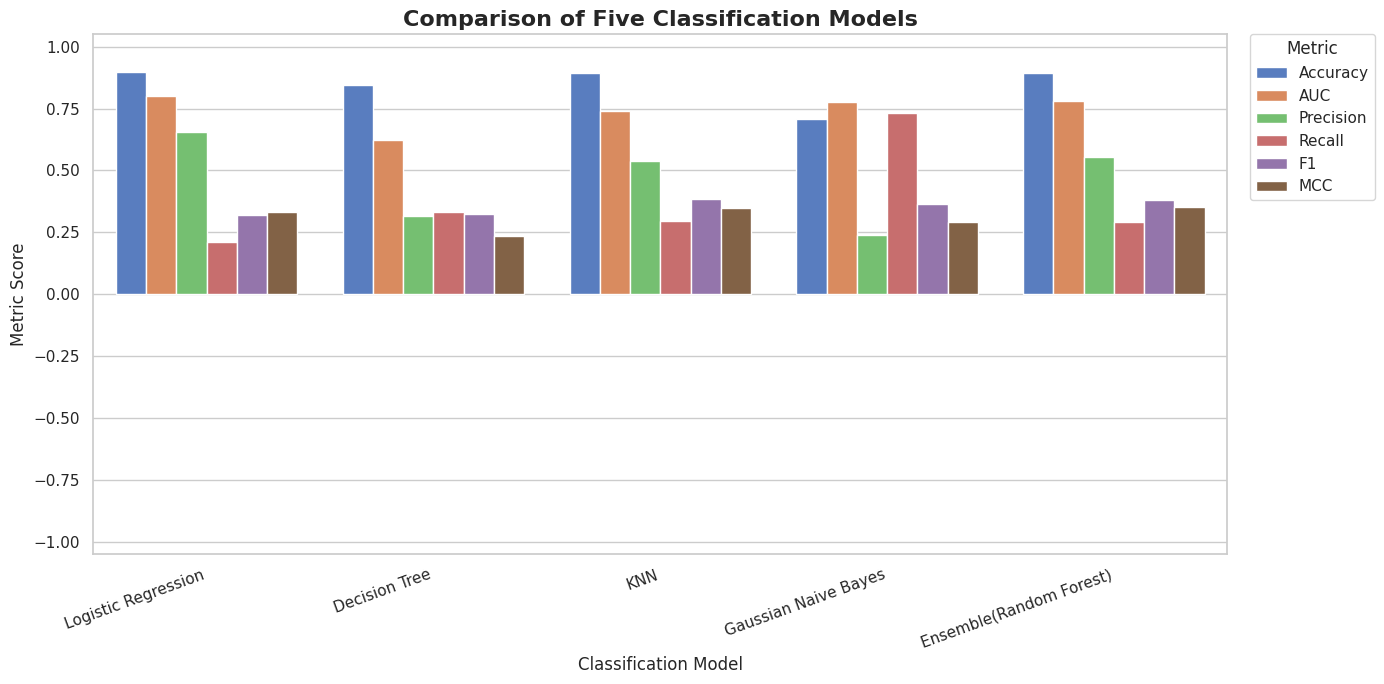

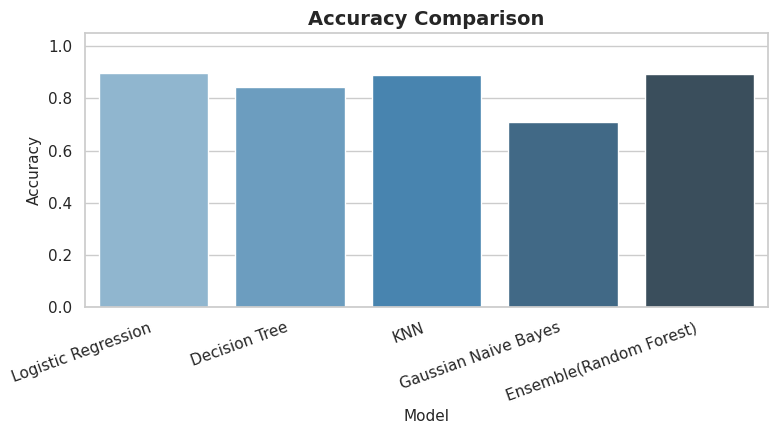

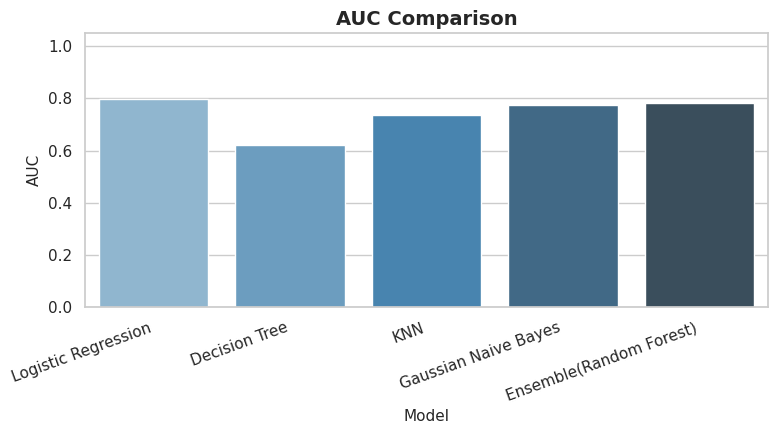

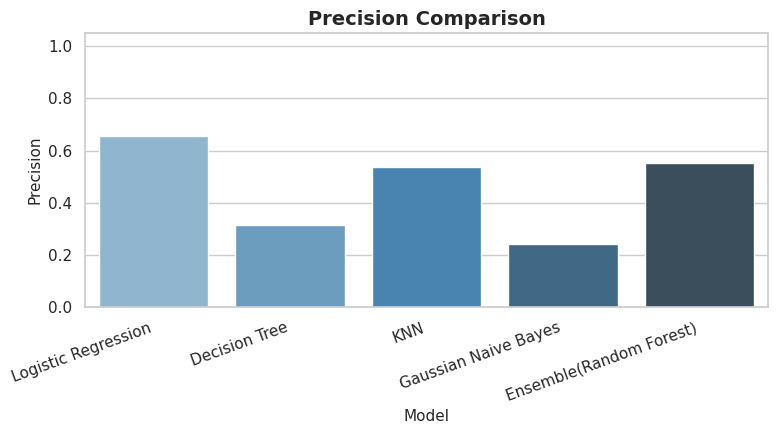

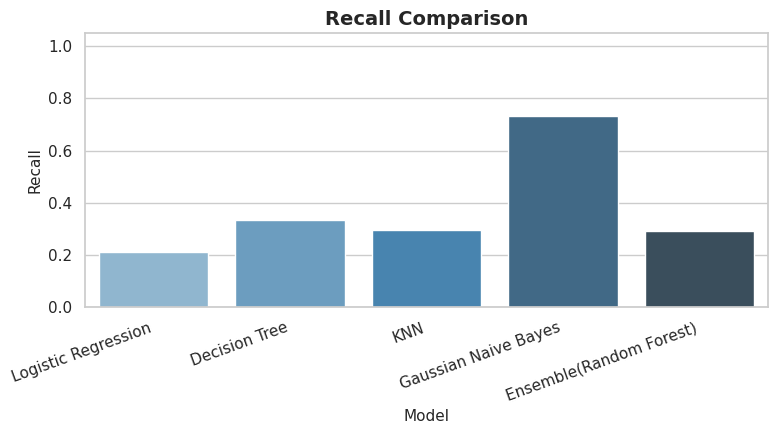

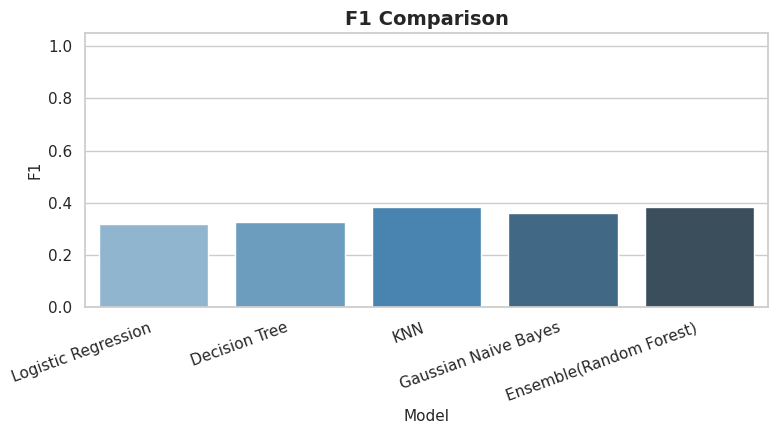

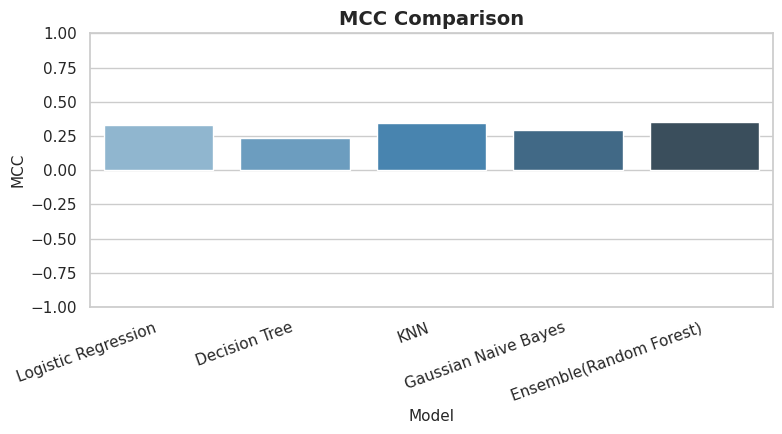

In [7]:
# Set Seaborn theme style
sns.set_theme(style="whitegrid")

metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]

# Prepare the data in long format for seaborn
results_long = results_df[metric_columns].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score"
)

# 1. Grouped bar chart comparing all metrics for all models
plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=results_long,
    x="Model",
    y="Score",
    hue="Metric",
    palette="muted"
)
plt.title("Comparison of Five Classification Models", fontsize=16, fontweight="bold")
plt.xlabel("Classification Model", fontsize=12)
plt.ylabel("Metric Score", fontsize=12)
plt.ylim(-1.05, 1.05)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# 2. Separate charts for each metric
for metric in metric_columns:
    plt.figure(figsize=(8, 4.5))
    ax_metric = sns.barplot(
        data=results_df.reset_index(),
        x="Model",
        y=metric,
        palette="Blues_d",
        hue="Model",
        legend=False
    )
    plt.title(f"{metric} Comparison", fontsize=14, fontweight="bold")
    plt.xlabel("Model", fontsize=11)
    plt.ylabel(metric, fontsize=11)
    plt.ylim((-1, 1) if metric == "MCC" else (0, 1.05))
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

## 8. Confusion matrices

Confusion matrices display true negatives, false positives, false negatives and true positives for each model.

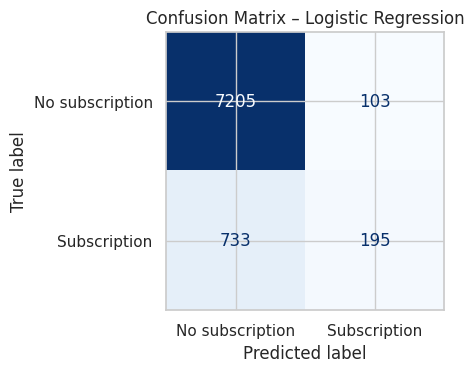

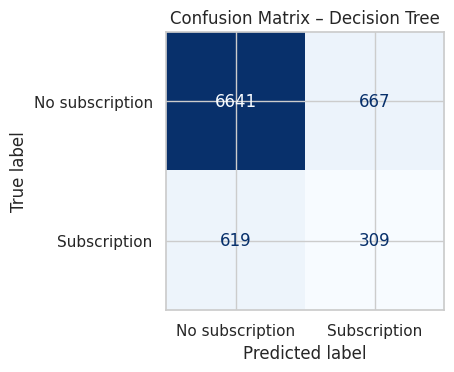

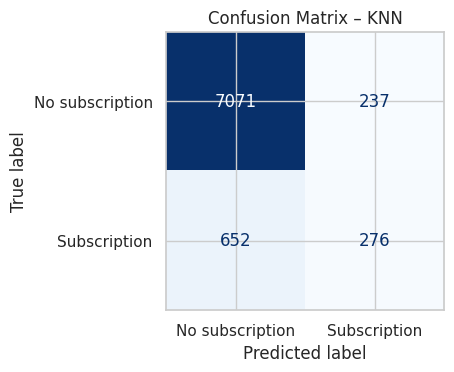

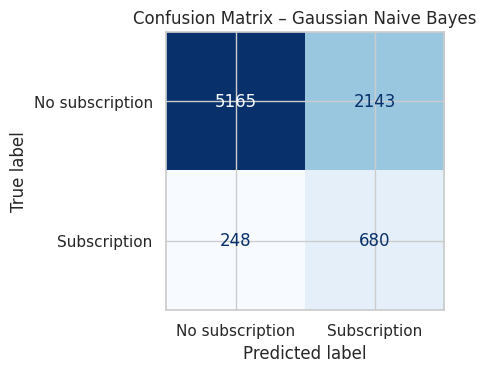

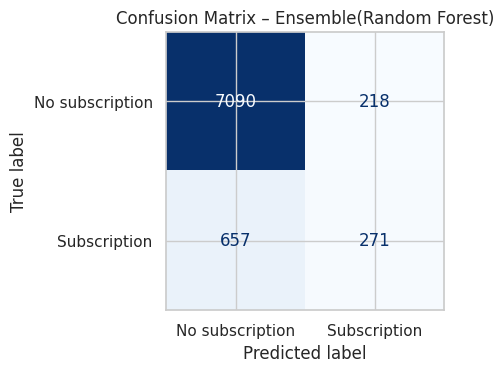

In [8]:
# Iterate over each trained estimator pipeline to visualize and plot its test-set confusion matrix
for model_name, pipe in fitted_models.items():
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_test, y_test,
        display_labels=["No subscription", "Subscription"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(f"Confusion Matrix – {model_name}")
    plt.tight_layout()
    plt.show()

## 9. Model observations and overall winner

To pick the best overall performer, we rank each model across all six evaluation criteria (where higher numbers represent stronger performance) and compute their average placement. The model with the lowest average rank is the winner. This approach provides a fair, multi-dimensional way to balance different strengths without assuming any single metric holds all the weight.

In [9]:
# Define standard diagnostic metrics to use for comparison
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]

# Compute how each model places across each individual metric (where lower rank numeric value is better)
rank_table = results_df[metric_columns].rank(ascending=False, method="average")

# Average out the ranks across all metrics to find the most suitable classifier
average_rank = rank_table.mean(axis=1).sort_values()
winner = average_rank.index[0]

# Loop through each model
observations = []
for model_name, row in results_df.iterrows():
    observations.append({
        "ML Model Name": model_name,
        "Observation about model performance": (
            f"Accuracy {row['Accuracy']:.3f}; AUC {row['AUC']:.3f}; "
            f"Precision {row['Precision']:.3f}; Recall {row['Recall']:.3f}; "
            f"F1 {row['F1']:.3f}; MCC {row['MCC']:.3f}."
        )
    })

# Set pandas display options to ensure the long string values are fully visible
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(observations))

print("Average rank (lower is better):")
display(average_rank.to_frame("average_rank"))

print("Overall winner based on average rank:", winner)

,ML Model Name,Observation about model performance
0,Logistic Regression,Accuracy 0.898; AUC 0.800; Precision 0.654; Recall 0.210; F1 0.318; MCC 0.332.
1,Decision Tree,Accuracy 0.844; AUC 0.623; Precision 0.317; Recall 0.333; F1 0.325; MCC 0.236.
2,KNN,Accuracy 0.892; AUC 0.738; Precision 0.538; Recall 0.297; F1 0.383; MCC 0.347.
3,Gaussian Naive Bayes,Accuracy 0.710; AUC 0.776; Precision 0.241; Recall 0.733; F1 0.363; MCC 0.293.
4,Ensemble(Random Forest),Accuracy 0.894; AUC 0.781; Precision 0.554; Recall 0.292; F1 0.382; MCC 0.351.


Average rank (lower is better):


,average_rank
Model,
Ensemble(Random Forest),2.166667
Logistic Regression,2.666667
KNN,2.666667
Gaussian Naive Bayes,3.500000
Decision Tree,4.000000


Overall winner based on average rank: Ensemble(Random Forest)


### Summary of Model Observations

| ML Model Name | Observation about model performance |
| :--- | :--- |
| **Logistic Regression** | • Behaves as a conservative classifier, making positive predictions only when it is highly confident.<br>• Achieves strong overall accuracy and precision, meaning that customers predicted as subscribers are likely to respond positively.<br>• However, the model fails to identify a large proportion of actual subscribers, resulting in relatively low recall.<br>• This approach is suitable for organizations with limited marketing resources that prioritize minimizing unnecessary customer contacts. |
| **Decision Tree** | • More proactive in identifying potential subscribers compared to Logistic Regression.<br>• Captures a reasonable number of customers who are likely to subscribe, improving recall.<br>• However, this comes at the cost of lower precision, as many non-subscribers are also classified as potential subscribers.<br>• Consequently, marketing campaigns based on this model may involve additional outreach efforts toward customers who are unlikely to respond. |
| **KNN** | • Delivers balanced and consistent predictive performance across evaluation metrics.<br>• Although it does not achieve the highest score in any single metric, it provides a reliable trade-off between precision and recall.<br>• The model avoids the extreme behaviors observed in more conservative or aggressive classifiers.<br>• This makes KNN a dependable baseline model for customer subscription prediction. |
| **Naive Bayes** | • The most aggressive model among the evaluated classifiers.<br>• Successfully identifies the majority of actual subscribers, achieving the highest recall.<br>• However, its precision is comparatively low, meaning that many non-subscribers are incorrectly predicted as subscribers.<br>• While the model maximizes customer coverage, it may significantly increase marketing costs due to a higher number of false-positive predictions. |
| **Random Forest (Ensemble)** | • Demonstrates the most stable and reliable overall performance among all models.<br>• Effectively balances precision and recall, ensuring that subscriber predictions remain both accurate and comprehensive.<br>• The ensemble structure reduces the risk of overfitting and improves generalization to unseen data.<br>• As a result, it offers strong predictive capability while maintaining consistent performance across multiple evaluation criteria. |
| **Overall Winner** | **Random Forest (Ensemble)** emerged as the best-performing model in this study.<br><br>• It consistently achieved strong results across multiple evaluation metrics rather than excelling in only one area.<br>• The model provides an effective balance between accurately identifying potential subscribers and limiting false-positive predictions.<br>• Its stability, robustness, and practical performance make it well-suited for real-world marketing applications.<br>• Based on the overall metric comparison and ranking, Random Forest represents the most reliable and deployment-ready solution for predicting customer subscription behavior.<br><br>**Conclusion:** Among all evaluated machine learning models, Random Forest offers the best combination <br> of predictive accuracy, recall, precision, and overall reliability, making it the preferred choice for supporting targeted marketing campaigns. |

## 10. Save results and fitted models

This saves the held-out test data, the model comparison table and five serialized end-to-end pipelines.

In [10]:
results_df.to_csv("model_comparison.csv")
print("Saved model_comparison.csv")
print("Saved test_data.csv")
print("Saved model files:")
for filename in sorted(os.listdir("model")):
    print(" -", os.path.join("model", filename))

Saved model_comparison.csv
Saved test_data.csv
Saved model files:
 - model/decision_tree.joblib
 - model/ensemble(random_forest).joblib
 - model/gaussian_naive_bayes.joblib
 - model/knn.joblib
 - model/logistic_regression.joblib
